# Taller: Evaluación de modelos y ajuste de hiperparámetros
**Machine Learning – Universidad Libre**

Usa datasets incluidos en scikit-learn y un conjunto sintético 1D (no requiere subir archivos). Ejecuta las celdas en orden.

| Paso | Actividad | Tiempo |
|------|-----------|--------|
| 1 | Cargar datos y dividir en entrenamiento y prueba | 10 min |
| 2 | Medir MAE, RMSE y R² en entrenamiento vs. prueba | 15 min |
| 3 | Detectar el sobreajuste: polinomios de grado 1 a 15 | 20 min |
| 4 | Validación cruzada: comparar 3 modelos | 25 min |
| 5 | GridSearchCV y RandomizedSearchCV | 30 min |
| 6 | Clasificación: matriz de confusión, F1 y AUC | 20 min |


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes, load_breast_cancer
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    KFold,
    GridSearchCV,
    RandomizedSearchCV,
    validation_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    RocCurveDisplay,
    ConfusionMatrixDisplay,
)

SEED = 42
plt.rcParams["figure.figsize"] = (7, 4)


def metricas_regresion(y_true, y_pred, n_features):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    n = len(y_true)
    k = n_features
    r2 = r2_score(y_true, y_pred)
    denom = n - k - 1
    r2_aj = np.nan if denom <= 0 else 1 - (1 - r2) * (n - 1) / denom
    return {
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2),
        "R2_aj": r2_aj,
    }


## Paso 1 – Cargar datos y dividir en entrenamiento y prueba (10 min)

Cargamos el dataset de diabetes de scikit-learn (442 pacientes, 10 variables clínicas, target continuo de progresión) y separamos **80 % entrenamiento / 20 % prueba**. El conjunto de prueba no se usa para elegir modelos ni hiperparámetros; la validación de los pasos 4 y 5 se hace con validación cruzada sobre el entrenamiento.


Filas, columnas: (442, 10)
Variables: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Entrenamiento: 353 | Prueba: 89

Target (entrenamiento):
count    353.00
mean     153.74
std       78.06
min       25.00
25%       86.00
50%      142.00
75%      214.00
max      346.00
Name: target, dtype: float64


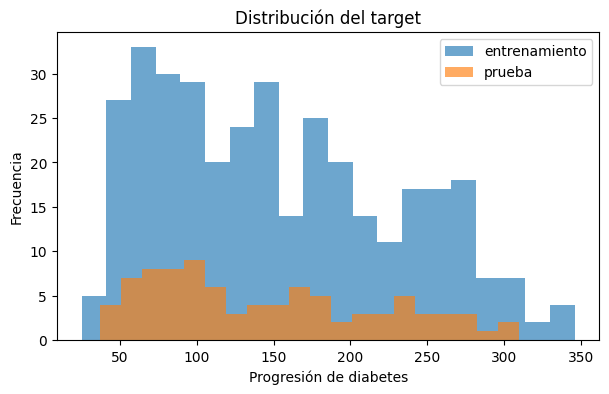

In [2]:
X, y = load_diabetes(return_X_y=True, as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

print("Filas, columnas:", X.shape)
print("Variables:", list(X.columns))
print("Entrenamiento:", len(X_train), "| Prueba:", len(X_test))
print()
print("Target (entrenamiento):")
print(y_train.describe().round(2))

fig, ax = plt.subplots()
ax.hist(y_train, bins=20, alpha=0.65, label="entrenamiento")
ax.hist(y_test, bins=20, alpha=0.65, label="prueba")
ax.set_xlabel("Progresión de diabetes")
ax.set_ylabel("Frecuencia")
ax.set_title("Distribución del target")
ax.legend()
plt.show()


**Interpretación.** El hold-out deja 353 filas para entrenar y **89 para probar**. Esas 89 no deben entrar en comparaciones de modelos ni en `GridSearchCV`: si el test participa en las decisiones, deja de ser una prueba y se convierte en otra validación. No separamos un tercer conjunto de validación porque los pasos 4 y 5 usarán validación cruzada sobre el entrenamiento. Las features de este dataset ya vienen aproximadamente centradas en scikit-learn; aun así, más adelante el `StandardScaler` irá **dentro** del `Pipeline` para no filtrar información del test.


## Paso 2 – Medir MAE, RMSE y R² en entrenamiento vs. prueba (15 min)

Entrenamos una **regresión lineal** (con `StandardScaler` en el pipeline, igual que en el paso 4) y comparamos MAE, RMSE, R² y R² ajustado en entrenamiento vs. prueba. El test se usa aquí como diagnóstico del modelo base, no para elegir entre modelos.


In [3]:
pipe_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("modelo", LinearRegression()),
]).fit(X_train, y_train)

k = X_train.shape[1]
tabla_baseline = pd.DataFrame({
    "train": metricas_regresion(y_train, pipe_lr.predict(X_train), k),
    "prueba": metricas_regresion(y_test, pipe_lr.predict(X_test), k),
}).round(3)
tabla_baseline


,train,prueba
MAE,43.484,42.794
RMSE,53.559,53.853
R2,0.528,0.453
R2_aj,0.514,0.382


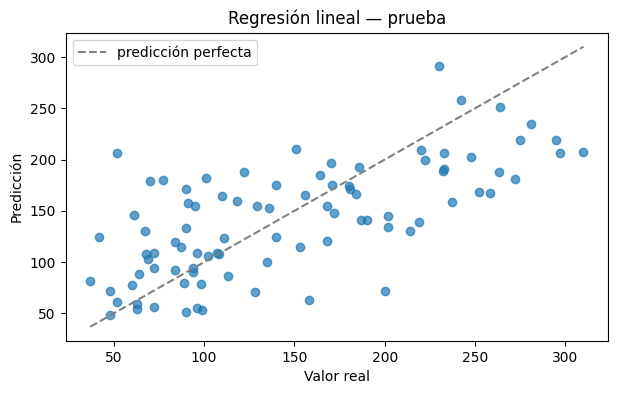

In [4]:
y_pred_test = pipe_lr.predict(X_test)
fig, ax = plt.subplots()
ax.scatter(y_test, y_pred_test, alpha=0.7)
lo, hi = min(y_test.min(), y_pred_test.min()), max(y_test.max(), y_pred_test.max())
ax.plot([lo, hi], [lo, hi], "--", color="gray", label="predicción perfecta")
ax.set_xlabel("Valor real")
ax.set_ylabel("Predicción")
ax.set_title("Regresión lineal — prueba")
ax.legend()
plt.show()


**Interpretación.** R² de entrenamiento 0.528 y de prueba 0.453, con MAE/RMSE casi iguales en ambos conjuntos (≈43.5 / 53.6 vs 42.8 / 53.9). Cuando train y test se parecen y el R² se queda a media tabla, el síntoma no es sobreajuste: el modelo **subajusta** (sesgo). La relación entre las 10 variables y la progresión no es del todo lineal, o faltan interacciones. El R² ajustado cae más en prueba (0.382) porque n=89 es pequeño frente a k=10. En el paso 3 veremos el patrón contrario: un modelo demasiado flexible.


## Paso 3 – Detectar el sobreajuste: polinomios de grado 1 a 15 (20 min)

Con las 10 variables de diabetes un polinomio de grado 15 genera millones de términos. Para ver el sobreajuste usamos una **curva sintética 1D**: 80 puntos de `y = sin(2πx) + ruido`, partidos 80/20. Ajustamos polinomios de grado 1 a 15 **solo con el train** de este experimento (no usamos diabetes).


In [5]:
rng = np.random.default_rng(SEED)
n_sint = 80
x1 = rng.uniform(0, 1, size=n_sint)
y1 = np.sin(2 * np.pi * x1) + rng.normal(0, 0.25, size=n_sint)
X1 = x1.reshape(-1, 1)
X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=0.20, random_state=SEED
)
print("Sintético — train:", len(X1_train), "| test:", len(X1_test))


Sintético — train: 64 | test: 16


In [6]:
filas = []
pipes_poly = {}
for grado in range(1, 16):
    pipe = Pipeline([
        ("poly", PolynomialFeatures(degree=grado, include_bias=True)),
        ("lin", LinearRegression(fit_intercept=False)),
    ]).fit(X1_train, y1_train)
    pipes_poly[grado] = pipe
    tr = metricas_regresion(y1_train, pipe.predict(X1_train), n_features=grado)
    te = metricas_regresion(y1_test, pipe.predict(X1_test), n_features=grado)
    filas.append({
        "grado": grado,
        "RMSE_train": tr["RMSE"],
        "RMSE_test": te["RMSE"],
        "R2_train": tr["R2"],
        "R2_test": te["R2"],
    })

tabla_polinomios = pd.DataFrame(filas)
grado_optimo = int(tabla_polinomios.loc[tabla_polinomios["RMSE_test"].idxmin(), "grado"])
print("Grado con menor RMSE de test:", grado_optimo)
tabla_polinomios.round(3)


Grado con menor RMSE de test: 5


,grado,RMSE_train,RMSE_test,R2_train,R2_test
0,1,0.492,0.495,0.588,0.546
1,2,0.485,0.502,0.598,0.534
2,3,0.237,0.296,0.904,0.838
3,4,0.236,0.288,0.905,0.847
4,5,0.225,0.237,0.914,0.896
5,6,0.224,0.237,0.914,0.896
6,7,0.224,0.239,0.915,0.894
7,8,0.224,0.238,0.915,0.895
8,9,0.218,0.253,0.919,0.882
9,10,0.218,0.253,0.919,0.881


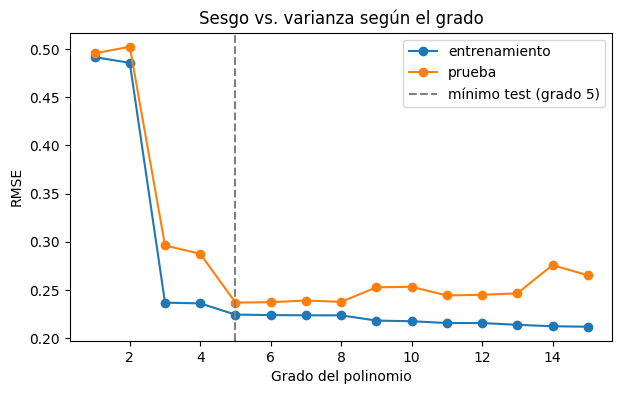

In [7]:
fig, ax = plt.subplots()
ax.plot(tabla_polinomios["grado"], tabla_polinomios["RMSE_train"], "o-", label="entrenamiento")
ax.plot(tabla_polinomios["grado"], tabla_polinomios["RMSE_test"], "o-", label="prueba")
ax.axvline(grado_optimo, color="gray", linestyle="--", label=f"mínimo test (grado {grado_optimo})")
ax.set_xlabel("Grado del polinomio")
ax.set_ylabel("RMSE")
ax.set_title("Sesgo vs. varianza según el grado")
ax.legend()
plt.show()


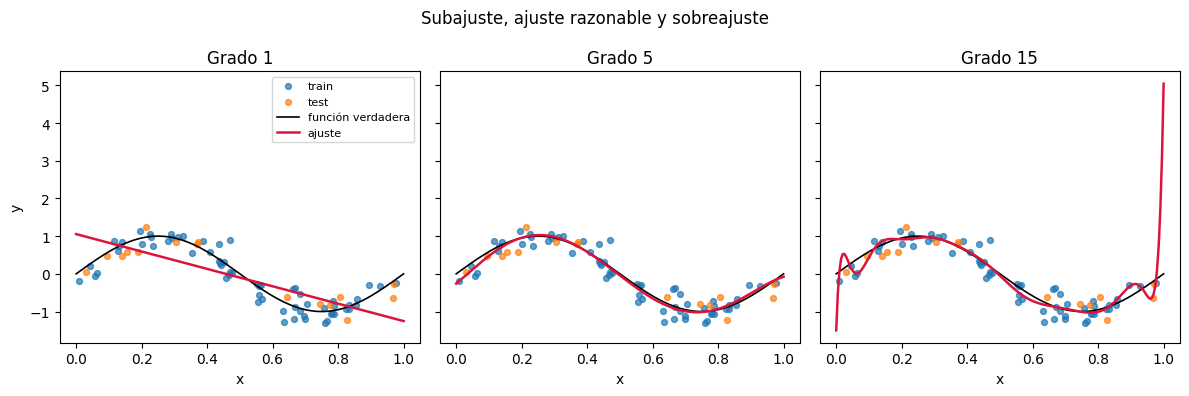

In [8]:
x_grid = np.linspace(0, 1, 200).reshape(-1, 1)
y_real = np.sin(2 * np.pi * x_grid.ravel())
grados_panel = [1, grado_optimo, 15]
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, g in zip(axes, grados_panel):
    ax.scatter(X1_train.ravel(), y1_train, s=18, alpha=0.7, label="train")
    ax.scatter(X1_test.ravel(), y1_test, s=18, alpha=0.7, label="test")
    ax.plot(x_grid, y_real, color="black", linewidth=1.2, label="función verdadera")
    ax.plot(x_grid, pipes_poly[g].predict(x_grid), color="crimson", linewidth=1.8, label="ajuste")
    ax.set_title(f"Grado {g}")
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].legend(fontsize=8)
fig.suptitle("Subajuste, ajuste razonable y sobreajuste")
plt.tight_layout()
plt.show()


**Interpretación.** Grado 1: RMSE de test ≈ 0.50; una recta no puede seguir un seno → **sesgo / subajuste**. Grado 5: mínimo de test (RMSE ≈ 0.237, R² ≈ 0.90) y el panel del medio sigue la onda. Grado 15: el error de train sigue bajando (≈ 0.212) mientras el de test sube (≈ 0.265) y la curva **persigue el ruido** → sobreajuste / varianza. Elegir el grado 5 con este test es solo para la figura. En un problema real el grado se elegiría con validación cruzada sobre el train, igual que en los pasos 4 y 5.


## Paso 4 – Validación cruzada: comparar 3 modelos (25 min)

Comparamos tres capacidades distintas **solo sobre el entrenamiento** de diabetes: regresión lineal (sesgo alto, varianza baja), árbol sin podar (varianza alta) y kNN. `KFold(5, shuffle=True)` con la misma semilla. El scoring de sklearn es `neg_root_mean_squared_error`; reportamos RMSE positivo.


Regresión lineal      RMSE medio=55.395  desv=2.361
Árbol de decisión     RMSE medio=80.411  desv=9.862
kNN                   RMSE medio=62.110  desv=3.580


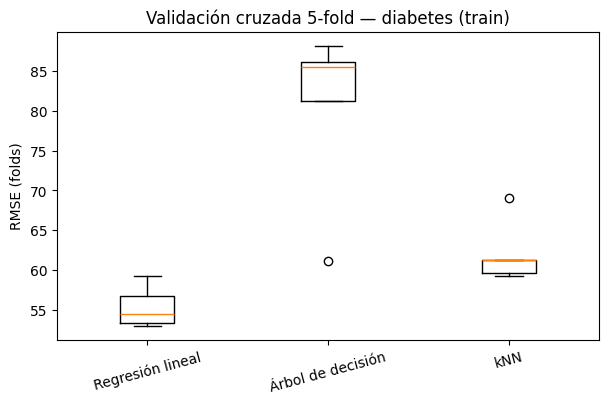

,modelo,RMSE_medio,RMSE_desv
0,Regresión lineal,55.395,2.361
1,Árbol de decisión,80.411,9.862
2,kNN,62.110,3.580


In [9]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

modelos_cv = {
    "Regresión lineal": Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", LinearRegression()),
    ]),
    "Árbol de decisión": Pipeline([
        ("modelo", DecisionTreeRegressor(random_state=SEED)),
    ]),
    "kNN": Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", KNeighborsRegressor()),
    ]),
}

rmse_cv = {}
for nombre, modelo in modelos_cv.items():
    scores = -cross_val_score(
        modelo, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error"
    )
    rmse_cv[nombre] = scores
    print(f"{nombre:20s}  RMSE medio={scores.mean():.3f}  desv={scores.std():.3f}")

resumen_cv = pd.DataFrame({
    "modelo": list(rmse_cv),
    "RMSE_medio": [v.mean() for v in rmse_cv.values()],
    "RMSE_desv": [v.std() for v in rmse_cv.values()],
}).round(3)

fig, ax = plt.subplots()
ax.boxplot(list(rmse_cv.values()))
ax.set_xticklabels(list(rmse_cv.keys()), rotation=15)
ax.set_ylabel("RMSE (folds)")
ax.set_title("Validación cruzada 5-fold — diabetes (train)")
plt.show()
resumen_cv


In [10]:
print("Estabilidad al variar k (solo regresión lineal)")
for k in (3, 5, 10):
    scores = -cross_val_score(
        modelos_cv["Regresión lineal"],
        X_train,
        y_train,
        cv=KFold(n_splits=k, shuffle=True, random_state=SEED),
        scoring="neg_root_mean_squared_error",
    )
    print(f"k={k:2d}  RMSE medio={scores.mean():.3f}  desv={scores.std():.3f}")


Estabilidad al variar k (solo regresión lineal)
k= 3  RMSE medio=55.791  desv=1.927


k= 5  RMSE medio=55.395  desv=2.361
k=10  RMSE medio=55.182  desv=4.716


**Interpretación.** Lineal 55.4 ± 2.4, kNN 62.1 ± 3.6, árbol 80.4 ± 9.9. El árbol por defecto crece sin límite y **sobreajusta** (varianza alta, folds inestables). kNN con 5 vecinos queda en el medio. La lineal, aunque en el paso 2 subajustaba un poco, es la más estable: no hay que elegir ganador por el error de entrenamiento. Al pasar k de 3 a 10 en la lineal, la media se mueve poco (55.8 → 55.2) y la desviación entre folds crece (1.9 → 4.7): folds más chicos, estimación más ruidosa.


## Paso 5 – GridSearchCV y RandomizedSearchCV (30 min)

Ajustamos hiperparámetros **dentro de un Pipeline y solo con el train**. `GridSearchCV` recorre una malla completa del árbol; `RandomizedSearchCV` muestra 15 combinaciones de kNN. La regresión lineal no tiene malla: su RMSE de CV es el del paso 4. El test de diabetes se abre al final, cuando el ganador ya está decidido.


In [11]:
grid = GridSearchCV(
    modelos_cv["Árbol de decisión"],
    param_grid={
        "modelo__max_depth": [1, 2, 3, 4, 5, 6, 8, None],
        "modelo__min_samples_leaf": [1, 2, 5, 10],
    },
    cv=cv,
    scoring="neg_root_mean_squared_error",
)
grid.fit(X_train, y_train)
print("Mejor árbol:", grid.best_params_)
print("RMSE CV árbol:", round(-grid.best_score_, 3))

rs = RandomizedSearchCV(
    modelos_cv["kNN"],
    param_distributions={
        "modelo__n_neighbors": list(range(1, 31)),
        "modelo__weights": ["uniform", "distance"],
        "modelo__p": [1, 2],
    },
    n_iter=15,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    random_state=SEED,
)
rs.fit(X_train, y_train)
print("Mejor kNN:", rs.best_params_)
print("RMSE CV kNN:", round(-rs.best_score_, 3))


Mejor árbol: {'modelo__max_depth': 2, 'modelo__min_samples_leaf': 1}
RMSE CV árbol: 63.392


Mejor kNN: {'modelo__weights': 'distance', 'modelo__p': 2, 'modelo__n_neighbors': 12}
RMSE CV kNN: 58.492


In [12]:
comparacion = pd.DataFrame([
    {
        "modelo": "Regresión lineal",
        "búsqueda": "—",
        "RMSE_CV": float(resumen_cv.set_index("modelo").loc["Regresión lineal", "RMSE_medio"]),
        "params": "—",
    },
    {
        "modelo": "Árbol de decisión",
        "búsqueda": "GridSearchCV",
        "RMSE_CV": float(-grid.best_score_),
        "params": grid.best_params_,
    },
    {
        "modelo": "kNN",
        "búsqueda": "RandomizedSearchCV",
        "RMSE_CV": float(-rs.best_score_),
        "params": rs.best_params_,
    },
]).round(3)

ganador_nombre = comparacion.loc[comparacion["RMSE_CV"].idxmin(), "modelo"]
estimadores = {
    "Regresión lineal": Pipeline([
        ("scaler", StandardScaler()),
        ("modelo", LinearRegression()),
    ]).fit(X_train, y_train),
    "Árbol de decisión": grid.best_estimator_,
    "kNN": rs.best_estimator_,
}
ganador = estimadores[ganador_nombre]
metricas_final = metricas_regresion(y_test, ganador.predict(X_test), n_features=X_train.shape[1])
print("Ganador según CV:", ganador_nombre)
print("Métricas en prueba:", {k: round(v, 3) for k, v in metricas_final.items()})
comparacion


Ganador según CV: Regresión lineal
Métricas en prueba: {'MAE': 42.794, 'RMSE': 53.853, 'R2': 0.453, 'R2_aj': 0.382}


,modelo,búsqueda,RMSE_CV,params
0,Regresión lineal,—,55.395,—
1,Árbol de decisión,GridSearchCV,63.392,"{'modelo__max_depth': 2, 'modelo__min_samples_..."
2,kNN,RandomizedSearchCV,58.492,"{'modelo__weights': 'distance', 'modelo__p': 2..."


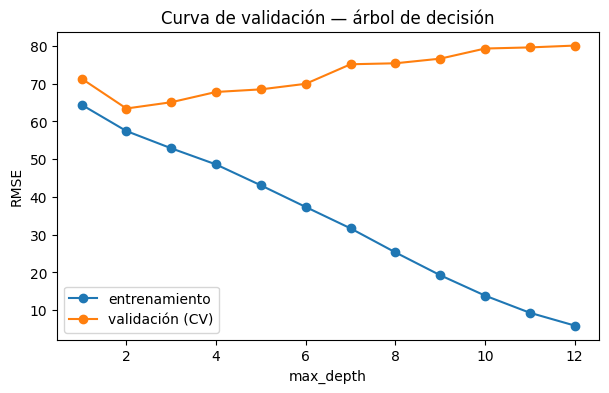

In [13]:
profundidades = list(range(1, 13))
train_scores, val_scores = validation_curve(
    modelos_cv["Árbol de decisión"],
    X_train,
    y_train,
    param_name="modelo__max_depth",
    param_range=profundidades,
    cv=cv,
    scoring="neg_root_mean_squared_error",
)
fig, ax = plt.subplots()
ax.plot(profundidades, -train_scores.mean(axis=1), "o-", label="entrenamiento")
ax.plot(profundidades, -val_scores.mean(axis=1), "o-", label="validación (CV)")
ax.set_xlabel("max_depth")
ax.set_ylabel("RMSE")
ax.set_title("Curva de validación — árbol de decisión")
ax.legend()
plt.show()


**Interpretación.** GridSearch deja el árbol en `max_depth=2` (RMSE CV ≈ 63.4): mejor que el árbol suelto del paso 4 (≈ 80) y peor que la lineal (≈ 55.4). RandomSearch deja kNN en 12 vecinos con distancia (RMSE CV ≈ 58.5): mejora el default y sigue detrás de la lineal. La búsqueda no inventa señal: en diabetes gana el modelo más simple. Grid explora las 32 combinaciones del árbol; Random prueba 15 de kNN y llega a un buen valor sin recorrer toda la malla. El `Pipeline` evita fugas porque el scaler (kNN) se ajusta en cada fold, no sobre el test. El test del ganador (MAE 42.794, RMSE 53.853, R² 0.453) coincide con el diagnóstico del paso 2: no lo usamos para elegir. La curva de `max_depth` debe mostrar el RMSE de train bajando y el de validación estancándose o subiendo al profundizar — el mismo patrón del paso 3, ahora con un hiperparámetro del árbol.


## Paso 6 – Clasificación: matriz de confusión, F1 y AUC (20 min)

Cambiamos de problema: `load_breast_cancer` (569 tumores, 30 variables). Clase 0 = **maligno**, clase 1 = **benigno**. Split 80/20 **estratificado**. Modelo: `StandardScaler` + `LogisticRegression` en un `Pipeline`.


Cáncer — train: 455 | test: 114
Balance test: {1: 72, 0: 42} (0=maligno, 1=benigno)
              pred maligno  pred benigno
real maligno            41             1
real benigno             1            71

              precision    recall  f1-score   support

     maligno      0.976     0.976     0.976        42
     benigno      0.986     0.986     0.986        72

    accuracy                          0.982       114
   macro avg      0.981     0.981     0.981       114
weighted avg      0.982     0.982     0.982       114

AUC = 0.995


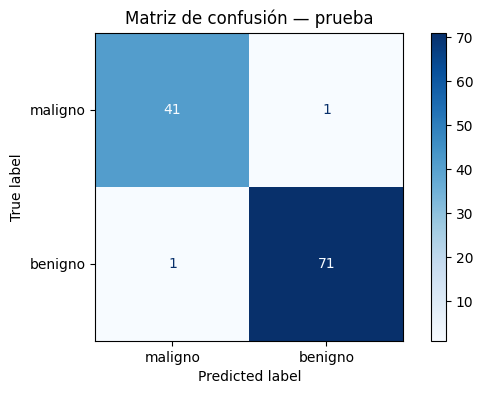

In [14]:
Xc, yc = load_breast_cancer(return_X_y=True, as_frame=True)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.20, stratify=yc, random_state=SEED
)
print("Cáncer — train:", len(Xc_train), "| test:", len(Xc_test))
print("Balance test:", yc_test.value_counts().to_dict(), "(0=maligno, 1=benigno)")

clf = Pipeline([
    ("scaler", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=1000, random_state=SEED)),
]).fit(Xc_train, yc_train)

pred = clf.predict(Xc_test)
etiquetas = ["maligno", "benigno"]
cm = pd.DataFrame(
    confusion_matrix(yc_test, pred),
    index=["real maligno", "real benigno"],
    columns=["pred maligno", "pred benigno"],
)
print(cm)
print()
print(classification_report(yc_test, pred, target_names=etiquetas, digits=3))
print("AUC =", round(roc_auc_score(yc_test, clf.predict_proba(Xc_test)[:, 1]), 3))

fig, ax = plt.subplots()
ConfusionMatrixDisplay.from_predictions(
    yc_test, pred, display_labels=etiquetas, cmap="Blues", ax=ax
)
ax.set_title("Matriz de confusión — prueba")
plt.show()


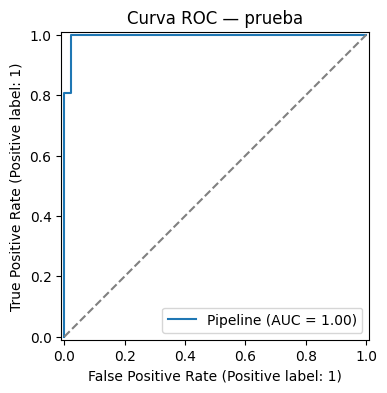

In [15]:
fig, ax = plt.subplots()
RocCurveDisplay.from_estimator(clf, Xc_test, yc_test, ax=ax)
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set_title("Curva ROC — prueba")
plt.show()


In [16]:
proba_benigno = clf.predict_proba(Xc_test)[:, 1]
print("Umbral sobre P(benigno)")
for t in (0.3, 0.5, 0.7):
    p = (proba_benigno >= t).astype(int)
    print(
        f"t={t:.1f}  precisión={precision_score(yc_test, p):.3f}  "
        f"recall={recall_score(yc_test, p):.3f}  F1={f1_score(yc_test, p):.3f}"
    )


Umbral sobre P(benigno)
t=0.3  precisión=0.973  recall=1.000  F1=0.986
t=0.5  precisión=0.986  recall=0.986  F1=0.986
t=0.7  precisión=0.985  recall=0.931  F1=0.957


**Interpretación.** En 114 pruebas hay 2 errores: 1 maligno declarado benigno (el falso negativo clínico) y 1 benigno declarado maligno. F1 0.976 / 0.986 y AUC 0.995: el modelo ordena muy bien las probabilidades. F1 resume precisión y recall en **un umbral**; el AUC resume el ranking en **todos** los umbrales — no se sustituyen. Bajar el umbral de benigno a 0.3 hace más fácil decir “benigno” (recall de benigno = 1.00) y puede dejar pasar malignos. Subirlo a 0.7 declara menos casos benignos (recall 0.931): más falsas alarmas, menos riesgo de perder un cáncer. En clínica el costo de un maligno perdido suele pesar más que el de una biopsia de más.


## Cierre — seis aprendizajes

1. **Hold-out:** el test existe para medir, no para decidir. 80/20 y semilla fija bastan si la selección se hace con CV en el train.
2. **Métricas de regresión:** MAE, RMSE y R² train vs prueba del baseline lineal mostraron **subajuste**, no sobreajuste (errores parecidos, R² ≈ 0.5).
3. **Polinomios 1–15:** grado bajo = sesgo, grado alto = varianza. El mínimo de test (grado 5) es una demo visual; en producción el grado se elige con CV.
4. **Validación cruzada:** comparar lineal, árbol y kNN con 5 folds evitó fiarse de un solo corte. Más folds estabilizan la media y ensanchan la desviación entre folds.
5. **Grid vs Random:** el `Pipeline` evita fugas. La búsqueda mejoró árbol y kNN, pero en diabetes siguió ganando la lineal: tunear no crea señal.
6. **Clasificación:** matriz de confusión + F1 + AUC + umbral. El umbral se mueve según el costo de un falso negativo (perder un maligno) frente a un falso positivo.
